<a href="https://colab.research.google.com/github/100522155/egci463/blob/main/Week6_2_Iris_Data_Exercise_with_Pipeline_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment on Iris data with pipeline and parameter Search

# Import Data
    Assume the data is in my(your) drive!!
    You can import the data from data upload

In [2]:
import numpy as np
import pandas as pd
import math as mt
from google.colab import drive
import io
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(io.BytesIO(uploaded["Iris.csv"]))


Saving Iris.csv to Iris.csv


# Show the data content

In [34]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


# Prepare the input data by splitting the data

In [35]:
from sklearn.model_selection import train_test_split
X_train, X_Val, y_train, y_Val = train_test_split(df.iloc[:,1:-1], df.iloc[:,-1], test_size=0.2, random_state=32)

**Check point 1**
Split for validation set

##Validation set
• For finding the RIGHT model
and parameters

• Model: linear, Bayesian, non-
linear

• Parameters: solvers and each
model's settings

In [36]:
#Separate the data between train, test & validation set
X,y =df.iloc[:,1:-1], df.iloc[:,-1]
#75% train set & validate set and 25% test set
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, stratify=y, random_state=32)
#Another train_test split to asign data between train and validation sets (75% train and 25% validation)
X_train, X_Val, y_train, y_Val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=32)
print(f"Train size: {len(X_train)} | Val size: {len(X_Val)} | Test size: {len(X_test)}")

Train size: 84 | Val size: 28 | Test size: 38


• Split off a test set first and lock it away

• Split the remaining training data again into
training and validation

• Final model = train on training, tune on
validation, report once on test

##Holdout technique

Splits the dataset directly: Training / Test (A) or Training / Validation / Test (B). This is what we did above.

**Advantages**
- Simple and easy
- Good for big enough data
- Fast

**Disadvantages**
- It can be biased
- A bad split can give an unpleasant outcome (see Check point 2: the accuracy changes with the random seed)
- May not suit a small data set (Iris has only 150 samples)

Creating PIPELINE

##Defining pipeline
A pipeline is an object which concatenates secuentially multiple steps of the data preparation, characteristics extraction and modelling in one only structure.

###Objective



1.   Prevent data leakage: Ensures that transformations as normalization or PCA are learned only in train data and are not affecting evalutation and test data
2.   Automatic data flow: Allows .fit(), .transform() , .predict() and similar functions to be applied to all the data set calling a single variable



####Implicit pipeline

In [37]:
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

pipe = make_pipeline(PCA(.97), LogisticRegression())
#Creates a Pipeline object, with automatic names based in each used class
#First step PCA with n_components = 0.97, then LogisticRegression model
pipe.fit(X_train, y_train)
#PCA applied to conservate 97% info and model = LogisticRegression,
#LogisticRegression adjust its classification coefficients using the matrix
#produced by PCA and y_train etiquetes
print("Val pred vs real:\n", np.array([pipe.predict(X_Val), y_Val]).T[:10])
print("Val acc:", pipe.score(X_Val, y_Val))
#Prediction and score

Val pred vs real:
 [['Iris-setosa' 'Iris-setosa']
 ['Iris-virginica' 'Iris-versicolor']
 ['Iris-setosa' 'Iris-setosa']
 ['Iris-versicolor' 'Iris-versicolor']
 ['Iris-versicolor' 'Iris-versicolor']
 ['Iris-setosa' 'Iris-setosa']
 ['Iris-virginica' 'Iris-virginica']
 ['Iris-virginica' 'Iris-virginica']
 ['Iris-versicolor' 'Iris-versicolor']
 ['Iris-setosa' 'Iris-setosa']]
Val acc: 0.9642857142857143


####Explicit Pipeline

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
#The main difference from the implicit and explicit pipeline:
#in explicit pipeline the naming of each component is needed

#List of steps with explicit names
steps = [
    ('Dim', PCA(n_components=2)),
    ('classify', LogisticRegression())
]

#Pipeline
pipe = Pipeline(steps)
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_Val)

#Use of explicit pipeline:
#Also, mid steps can be included
pipe_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.97)),
    ("clf", LogisticRegression())
])

#With multiple steps in the same class (PCA(0.92) and PCA(3)), to asign
#characteristic names to each step

#Cleaner hiperparameters in GridsearchCV



In [39]:
#This is an explicit pipeline function
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

def pipeline_ncomp(n):
  steps = [('Dim', PCA(n_components=n)), ('classify', LogisticRegression())]
  return Pipeline(steps)

In [40]:
# define the pipeline object.
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

#Pipeline ejecution repeated times
for n in range(1,5):
  pipe = pipeline_ncomp(n)
  pipe.fit(X_train, y_train)
  y_pred = pipe.predict(X_Val)
  print(f"Component {n}")
  print("%.2f"%accuracy_score(y_Val, y_pred))

Component 1
0.89
Component 2
0.96
Component 3
0.96
Component 4
0.96


###Repeating various times the pipelines brings benefits:

   Optimizing hyperparameters without overfitting (GridSearchCV / RandomSearch):
   In this code we increase with each interaction n_components and see how the accuracy varies depending on how the data is compacted in 1,2,3 or 4 dimensions in this particular case.
   
   Iterating through the pipeline to test different configurations (for example, modifying the number of PCA components $n \in \{1, 2, 3, 4\}$ or the regularization strength $C$) allows for a fair comparison of which combination yields the best validation accuracy before touching the final test set.
   
   
   Holdout bias: In small datasets, to evaluate a pipeline usually gives highly optimistic and tricky results if the random partition is in favor. Repeat n times different partitions (K-Fold Cross-Validation) lets us obtain a good real performance mean $E = \frac{1}{k}\sum E_i$ (Here we are not doing different partitions)



####Complete Evaluation Workflow Pipeline

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Create the complete evaluation Pipeline
complete_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=3)),
    ('clf', LogisticRegression(max_iter=1000))
])

# 2. Fit the pipeline using only the training set
complete_pipeline.fit(X_train, y_train)

# 3. Evaluate on the validation set (for tuning / verification)
y_pred_val = complete_pipeline.predict(X_Val)
print(f"Validation Set Accuracy (X_Val): {accuracy_score(y_Val, y_pred_val):.4f}")

# 4. Detailed validation report (the test set stays locked until the end of the notebook)
print(classification_report(y_Val, y_pred_val))

Validation Set Accuracy (X_Val): 0.9643
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00         9
Iris-versicolor       1.00      0.89      0.94         9
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.96        28
      macro avg       0.97      0.96      0.96        28
   weighted avg       0.97      0.96      0.96        28



Expreiment LDA + 2D projection

PCA + LogReg -> Validation accuracy: 0.9643
PCA + LDA + LogReg -> Validation accuracy: 0.9643


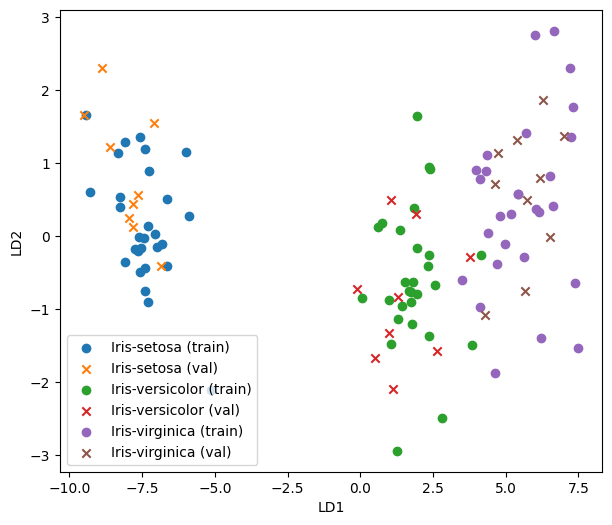

In [42]:
#Experiment: add LDA between PCA and logistic regression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
import matplotlib.pyplot as plt

# Pipeline without LDA
pipe_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=3)),
    ('clf', LogisticRegression(max_iter=1000))
])

# Pipeline with LDA (3 classes -> at most 2 LDA components)
pipe_lda = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=3)),
    ('lda', LDA(n_components=2)), #Linear discriminant Analysis,
    #it is used form dimensionality reduction and classification
    #its a supervised method, its objenctive is to project data maximizing
    #separability between classes, so they can be easily distinguished
    ('clf', LogisticRegression(max_iter=1000))
])

pipe_pca.fit(X_train, y_train)
print("PCA + LogReg -> Validation accuracy:", round(pipe_pca.score(X_Val, y_Val), 4))
pipe_lda.fit(X_train, y_train)
print("PCA + LDA + LogReg -> Validation accuracy:", round(pipe_lda.score(X_Val, y_Val), 4))

# 2D projection of LDA (all steps except the classifier)
Z_train = pipe_lda[:-1].transform(X_train)
Z_val = pipe_lda[:-1].transform(X_Val)

plt.figure(figsize=(7, 6))
for c in pipe_lda.classes_:
    plt.scatter(Z_train[y_train == c, 0], Z_train[y_train == c, 1], label=f"{c} (train)")
    plt.scatter(Z_val[y_Val == c, 0], Z_val[y_Val == c, 1], marker="x", label=f"{c} (val)")

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.legend()
plt.show()

**Check point2**
Try modifying Random seed..> any changes?

In [43]:
from sklearn.metrics import accuracy_score

for seed in [10, 22, 42, 99]:
    # Create different divisions with different seeds
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_train, y_train, test_size=0.25, random_state=seed)

    for n in range(1, 5):
        pipe = pipeline_ncomp(n)
        pipe.fit(X_tr, y_tr)
        y_pred = pipe.predict(X_va)
        print(f"Seed: {seed} | Componentes: {n} | Val Accuracy: {accuracy_score(y_va, y_pred):.2f}")

Seed: 10 | Componentes: 1 | Val Accuracy: 0.90
Seed: 10 | Componentes: 2 | Val Accuracy: 0.90
Seed: 10 | Componentes: 3 | Val Accuracy: 1.00
Seed: 10 | Componentes: 4 | Val Accuracy: 1.00
Seed: 22 | Componentes: 1 | Val Accuracy: 0.90
Seed: 22 | Componentes: 2 | Val Accuracy: 0.90
Seed: 22 | Componentes: 3 | Val Accuracy: 0.95
Seed: 22 | Componentes: 4 | Val Accuracy: 0.95
Seed: 42 | Componentes: 1 | Val Accuracy: 0.95
Seed: 42 | Componentes: 2 | Val Accuracy: 0.95
Seed: 42 | Componentes: 3 | Val Accuracy: 0.95
Seed: 42 | Componentes: 4 | Val Accuracy: 0.95
Seed: 99 | Componentes: 1 | Val Accuracy: 0.95
Seed: 99 | Componentes: 2 | Val Accuracy: 0.95
Seed: 99 | Componentes: 3 | Val Accuracy: 1.00
Seed: 99 | Componentes: 4 | Val Accuracy: 0.95


We can see how the accuracy changes due to the different distribution of samples in small datasets

# Cross Validation

**Check point3**
Try use stratified cross validation

##Definition of cross validation

Cross validation divides the data in folds randomly.

Each fold can contain random number of data or not, depending on the stratification.
the Stratified variant guarantees that each fold (or block) has the same proportion of each class as the full dataset.

Manual Cross Validation. Also called the Monte Carlo Cross-Validation. Mixes the dataset in each iteration (like card games) and obtains the accuracy. Each iteration doesnt conserve memory.

In [44]:
#Test
#Try
X_exp = np.array([[1, 2], [3, 4], [1, 2], [3, 4], [1, 2], [3, 4]])
y_exp = np.array([0, 0, 0, 1, 1, 1])

from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=0)
sss.get_n_splits(X_exp, y_exp)
#Simply counting the split --> optimize it if you want
i=1;
for train_index, test_index in sss.split(X_exp, y_exp):
   print("Split",i,"TRAIN:", train_index, "TEST:", test_index)
   i=i+1

Split 1 TRAIN: [2 5 1 3] TEST: [0 4]
Split 2 TRAIN: [0 4 3 1] TEST: [2 5]
Split 3 TRAIN: [0 4 3 1] TEST: [2 5]
Split 4 TRAIN: [5 4 1 2] TEST: [0 3]
Split 5 TRAIN: [1 5 2 4] TEST: [0 3]


We are now going to add a pipeline to see the effect on the accuracy.

In [45]:
# define the pipeline object.
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

#(Random subsampling, not K-fold: the name is kept from the original)
def pipeline_ncomp_Kfold(n):
    steps = [('Dim', PCA(n_components=n)), ('classify', LogisticRegression())]
    return Pipeline(steps)


ss1 = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=0)
#Only X_train/y_train are used: the test set stays locked and X_train is NOT overwritten
ss1.get_n_splits(X_train, y_train)

long_scores = []
for n in range(1, 5):
    scores = []
    for train_index, val_index in ss1.split(X_train, y_train):
      X_tr_cv, X_va_cv = X_train.iloc[train_index], X_train.iloc[val_index]
      y_tr_cv, y_va_cv = y_train.iloc[train_index], y_train.iloc[val_index]

      pipe = pipeline_ncomp_Kfold(n)
      pipe.fit(X_tr_cv, y_tr_cv)
      y_pred = pipe.predict(X_va_cv)
      scores.append(round(accuracy_score(y_va_cv, y_pred),2))
    mean_acc = np.mean(scores)
    std_acc = np.std(scores)
    print(f"Component {n} -> Mean accuracy: {mean_acc:.2f} (+/- {std_acc:.2f})")
    long_scores.append(f"Component {n}")
    long_scores.append(scores)


print()
for elm in long_scores:
  print(elm)

Component 1 -> Mean accuracy: 0.92 (+/- 0.03)
Component 2 -> Mean accuracy: 0.96 (+/- 0.03)
Component 3 -> Mean accuracy: 0.98 (+/- 0.03)
Component 4 -> Mean accuracy: 0.96 (+/- 0.03)

Component 1
[0.94, 0.88, 0.94, 0.94, 0.88]
Component 2
[0.94, 0.94, 1.0, 1.0, 0.94]
Component 3
[1.0, 0.94, 1.0, 1.0, 0.94]
Component 4
[0.94, 0.94, 1.0, 1.0, 0.94]


In [46]:
#Use Different randomstate/ split to check!!
#Lets try different randomstate
long_scores = []
for seed in [10, 22, 42, 99]:
    # Create different divisions with different seeds
    ss1 = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=seed)
    ss1.get_n_splits(X_train, y_train)

    for n in range(1, 5):
        scores = []
        for train_index, val_index in ss1.split(X_train, y_train):
          X_tr_cv, X_va_cv = X_train.iloc[train_index], X_train.iloc[val_index]
          y_tr_cv, y_va_cv = y_train.iloc[train_index], y_train.iloc[val_index]

          pipe = pipeline_ncomp_Kfold(n)
          pipe.fit(X_tr_cv, y_tr_cv)
          y_pred = pipe.predict(X_va_cv)
          scores.append(round(accuracy_score(y_va_cv, y_pred),2))
        mean_acc = np.mean(scores)
        std_acc = np.std(scores)
        print(f"Component {n} -> Mean accuracy: {mean_acc:.2f} (+/- {std_acc:.2f})")
        long_scores.append(scores)

print()


for i, scores in enumerate(long_scores):
    comp = (i % 4) + 1
    seed_idx = i // 4
    print(f"Seed Index {seed_idx} | Component {comp}: {scores}")

Component 1 -> Mean accuracy: 0.93 (+/- 0.04)
Component 2 -> Mean accuracy: 0.94 (+/- 0.05)
Component 3 -> Mean accuracy: 0.99 (+/- 0.02)
Component 4 -> Mean accuracy: 0.98 (+/- 0.03)
Component 1 -> Mean accuracy: 0.92 (+/- 0.06)
Component 2 -> Mean accuracy: 0.94 (+/- 0.05)
Component 3 -> Mean accuracy: 0.98 (+/- 0.03)
Component 4 -> Mean accuracy: 0.96 (+/- 0.03)
Component 1 -> Mean accuracy: 0.92 (+/- 0.07)
Component 2 -> Mean accuracy: 0.96 (+/- 0.05)
Component 3 -> Mean accuracy: 0.96 (+/- 0.03)
Component 4 -> Mean accuracy: 0.95 (+/- 0.04)
Component 1 -> Mean accuracy: 0.93 (+/- 0.02)
Component 2 -> Mean accuracy: 0.96 (+/- 0.03)
Component 3 -> Mean accuracy: 0.99 (+/- 0.02)
Component 4 -> Mean accuracy: 0.99 (+/- 0.02)

Seed Index 0 | Component 1: [0.88, 0.94, 0.94, 1.0, 0.88]
Seed Index 0 | Component 2: [0.88, 0.94, 1.0, 1.0, 0.88]
Seed Index 0 | Component 3: [0.94, 1.0, 1.0, 1.0, 1.0]
Seed Index 0 | Component 4: [0.94, 0.94, 1.0, 1.0, 1.0]
Seed Index 1 | Component 1: [0.82, 0.

**Check point4** Try use  cross validation

In the checkpoint3 it had to be separated manually the index of the matrixs, train in the pipeline with .fit() and then predict the results.

cross_val_score --> easier, automatic. Throw the pipeline, the matrix the tags (y) and the strategy so scikit-learn does the rest:


1.   Divides thr data in folds/blocks
2.   Does the PCA, the fitting and applys LogistigRegression to that fold's subdata without dataleaking
3. Evaluates the model in that fold and gives back a Numpy array with the corresponding fixes.



Automatic cross validation

In [47]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
pipe = pipeline_ncomp(n=2)

#Only the training part: the test set is never used in cross-validation
scores = cross_val_score(pipe, X_train, y_train, cv=kf)

print(f"Puntuation per Fold: {scores}")
print(f"Mean accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

Puntuation per Fold: [0.94117647 1.         0.94117647 0.82352941 1.        ]
Mean accuracy: 0.9412 (+/- 0.0644)


In [48]:
#Lets apply the pipeline
import numpy as np
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for n in range(1, 5):
    pipe = pipeline_ncomp(n)
    scores = cross_val_score(pipe, X_train, y_train, cv=kf)

    mean_acc = scores.mean()
    std_acc = scores.std()
    print(f"Component {n} -> Accuracy mean: {mean_acc:.4f} (+/- {std_acc:.4f})")

    print(f"Puntuation per Fold: {scores}")
    print(f"Mean accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

Component 1 -> Accuracy mean: 0.9176 (+/- 0.0798)
Puntuation per Fold: [0.94117647 1.         0.82352941 0.82352941 1.        ]
Mean accuracy: 0.9176 (+/- 0.0798)
Component 2 -> Accuracy mean: 0.9412 (+/- 0.0644)
Puntuation per Fold: [0.94117647 1.         0.94117647 0.82352941 1.        ]
Mean accuracy: 0.9412 (+/- 0.0644)
Component 3 -> Accuracy mean: 0.9765 (+/- 0.0288)
Puntuation per Fold: [0.94117647 1.         1.         0.94117647 1.        ]
Mean accuracy: 0.9765 (+/- 0.0288)
Component 4 -> Accuracy mean: 0.9765 (+/- 0.0288)
Puntuation per Fold: [0.94117647 1.         1.         0.94117647 1.        ]
Mean accuracy: 0.9765 (+/- 0.0288)


###StratifiedKFold

Kfold divides the dataset in K blocks randomly or secuentually without minding the etiquetes or data classes.

StratifiedKfold divides the dataset forcing that each split contains the same proportion of classes as the other ones

In [49]:
import numpy as np
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

#shuffle=True --> randomnes
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

for n in range(1, 5):

    pipe = pipeline_ncomp(n)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv_strategy, scoring='accuracy')

    print(f"Componentes: {n} | Accuracy CV Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")

Componentes: 1 | Accuracy CV Mean: 0.9294 (+/- 0.0440)
Componentes: 2 | Accuracy CV Mean: 0.9529 (+/- 0.0235)
Componentes: 3 | Accuracy CV Mean: 0.9765 (+/- 0.0288)
Componentes: 4 | Accuracy CV Mean: 0.9765 (+/- 0.0288)


Leave-one-out

Special and extreme case of cross validation (K = N), only one sample is kept for validation:

1.  Separate a single sample to use for validation.

2. Use the remaining $N - 1$ samples to train the model.

3. Evaluate the model with that single left-out sample and record whether it succeeded or failed.

4. Repeat this process $N$ times, so that every sample serves as the validation sample exactly once.

It doesn't throw away data and has low bias, but its variance can be large (each score is only 0 or 1).
It is computationally expensive: the model is trained N times, so the time is much higher than with K=3, 5 or 10.

In [50]:
#Number of K's: compare K=3, 5, 10 and Leave-One-Out (on the training set only)
import time
from sklearn.model_selection import LeaveOneOut

pipe = pipeline_ncomp(3)   # PCA(3) + LogisticRegression

cv_options = {
    "K=3":  StratifiedKFold(n_splits=3,  shuffle=True, random_state=0),
    "K=5":  StratifiedKFold(n_splits=5,  shuffle=True, random_state=0),
    "K=10": StratifiedKFold(n_splits=10, shuffle=True, random_state=0),
    "Leave-One-Out (K=N)": LeaveOneOut(),
}
#
print(len(X_train), len(y_train),len(X_Val), len(y_Val))
for name, cv in cv_options.items():
    t0 = time.time()
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    print(f"{name:22s} | experiments: {len(scores):3d} | "
          f"Mean acc: {scores.mean():.4f} (+/- {scores.std():.4f}) | time: {time.time()-t0:.2f}s")

84 84 28 28
K=3                    | experiments:   3 | Mean acc: 0.9643 (+/- 0.0000) | time: 0.04s
K=5                    | experiments:   5 | Mean acc: 0.9765 (+/- 0.0288) | time: 0.07s
K=10                   | experiments:  10 | Mean acc: 0.9764 (+/- 0.0473) | time: 0.13s
Leave-One-Out (K=N)    | experiments:  84 | Mean acc: 0.9762 (+/- 0.1525) | time: 1.18s


##Number of K's

| Large K | Small K |
|---|---|
| Many experiments | Few experiments |
| The variance of the errors can be large | Low variance tendency |
| Time consuming | Less time consuming |
| May have lower bias | Bias toward a particular subset can be high |

Leave-One-Out is the special case K = N (here N = number of training samples). It is usually used for small datasets.
Note: in Leave-One-Out each fold has only one sample, so every score is 0 or 1 and its std is not comparable with the other options; compare the **mean** and the **time**.

**Check point5** Using GridSearch

###Gridsearch

Completes the automatization
Deletes the manual loop
Searches the optimal number of principal components and trains the final model in one step

In [51]:
#This is a search for the best number of components for PCA
from sklearn.model_selection import GridSearchCV

parameters = {'n_components': [1,2,3,4] } #N_components possible
grid = GridSearchCV(PCA(),param_grid=parameters, cv=5) #Does the gridsearch

steps = [('Dim',grid),
('classify', LogisticRegression())]
# Steps of the pipeline, first it evaluates the best PCA components and
#transforms X_train and gives the reduced matrix to the model


from sklearn.pipeline import Pipeline

pipeline = Pipeline(steps)
# define the pipeline object.



In [52]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('Dim',
                 GridSearchCV(cv=5, estimator=PCA(),
                              param_grid={'n_components': [1, 2, 3, 4]})),
                ('classify', LogisticRegression())])

In [53]:
best_pca_grid = pipeline.named_steps['Dim'] #This is the use of explicit
print("Best n_components for PCA:", best_pca_grid.best_params_)

Best n_components for PCA: {'n_components': 3}


Whole train code

 'clf__C': determines the search space for the hyperparameter C of the model inside. Completely related to LogisticRegression, controls the complexity of the model. The best value is selected.
 In gridsearch it has to be discrete, in Random search can be continuous

In [54]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, KFold


# Encapsulates data scaling, dimensionality reduction, and classification into a single object.
# This prevents data leakage by ensuring transformations are fitted ONLY on training folds.
pipe = Pipeline([
    ("scaler", StandardScaler()),                 # Step 1: Standardize features (mean=0, std=1)
    ("pca", PCA()),                               # Step 2: Apply Principal Component Analysis
    ("clf", LogisticRegression(max_iter=1000))    # Step 3: Train Logistic Regression model
])

# Define the search space for parameters.
# Syntax: 'stepname__parametername' maps the parameter directly to the target pipeline step.
parameters = {
    'pca__n_components': [1, 2, 3, 4],  # Test 1, 2, 3, and 4 components inside the 'pca' step
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]       # Discrete list of C values (GridSearch needs explicit values); 1000 added
    #because C=100 was at the edge of the grid
}

# Set up a 5-fold cross-validation scheme with shuffling and a fixed random seed for reproducibility.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# GridSearchCV wraps the entire pipeline:
# - Tests all combinations in 'parameters'
# - Uses the specified KFold strategy ('cv=kf')
# - Fits all models on the training set (X_train, y_train) and automatically refits the best one.
grid = GridSearchCV(pipe, param_grid=parameters, cv=kf).fit(X_train, y_train)

# Print the optimal hyperparameter combination found during validation
print("Best parameters:", grid.best_params_)

# Print the highest average validation accuracy score achieved by the best combination
print("Best cross-validation score:", grid.best_score_)

# Output the complete fitted Pipeline instance using the best parameters
print("Best estimator model:", grid.best_estimator_)

print()
# Print the detailed dictionary containing all evaluation metrics per split and parameter combination
print("Complete cross-validation results dictionary:")


print()
# Sort and list all available outcome key names in the cv_results_ dictionary for inspection
print("Sorted keys available in cv_results_:")
print(sorted(grid.cv_results_.keys())[:4])
print(sorted(grid.cv_results_.keys())[4:8])
print(sorted(grid.cv_results_.keys())[8:12])
print(sorted(grid.cv_results_.keys())[12:])

# Convert the search history dictionary into a DataFrame for structured inspection
results_df = pd.DataFrame(grid.cv_results_)
print("\nSummary of tested parameter combinations:")
print(results_df[['param_pca__n_components', 'param_clf__C', 'mean_test_score', 'rank_test_score']])

Best parameters: {'clf__C': 1, 'pca__n_components': 3}
Best cross-validation score: 0.9647058823529411
Best estimator model: Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA(n_components=3)),
                ('clf', LogisticRegression(C=1, max_iter=1000))])

Complete cross-validation results dictionary:

Sorted keys available in cv_results_:
['mean_fit_time', 'mean_score_time', 'mean_test_score', 'param_clf__C']
['param_pca__n_components', 'params', 'rank_test_score', 'split0_test_score']
['split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score']
['std_fit_time', 'std_score_time', 'std_test_score']

Summary of tested parameter combinations:
    param_pca__n_components  param_clf__C  mean_test_score  rank_test_score
0                         1         0.001         0.596324               28
1                         2         0.001         0.619853               25
2                         3         0.001         0.619853               25
3           

In [55]:
print(grid.cv_results_)

{'mean_fit_time': array([0.01047034, 0.00958962, 0.00937533, 0.00932207, 0.00976892,
       0.01192274, 0.00948639, 0.01046348, 0.00874648, 0.00996466,
       0.01372662, 0.00898371, 0.00925431, 0.00966048, 0.00944805,
       0.00953884, 0.00962052, 0.01109748, 0.01140013, 0.01140819,
       0.0103179 , 0.01137071, 0.01242652, 0.01208816, 0.01556125,
       0.01066923, 0.01111407, 0.0117878 ]), 'std_fit_time': array([1.94518437e-03, 5.41241754e-04, 5.42185510e-04, 5.53695633e-04,
       1.41150020e-03, 4.68735310e-03, 5.88118634e-04, 2.41850460e-03,
       3.07223728e-04, 1.73848273e-03, 6.07170107e-03, 3.23528498e-04,
       1.98366871e-04, 2.46437452e-04, 1.50483869e-04, 5.80777871e-05,
       2.19469118e-04, 1.46124303e-03, 2.97257454e-04, 1.11480138e-03,
       2.62015254e-04, 5.98668082e-04, 1.12805435e-03, 8.34040242e-04,
       4.52611606e-03, 7.05875592e-04, 1.32794243e-03, 1.59050515e-03]), 'mean_score_time': array([0.0034512 , 0.00328708, 0.00334492, 0.00411439, 0.00337658,
 

**Try to find the best estimator?**

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00         9
Iris-versicolor       1.00      0.89      0.94         9
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.96        28
      macro avg       0.97      0.96      0.96        28
   weighted avg       0.97      0.96      0.96        28



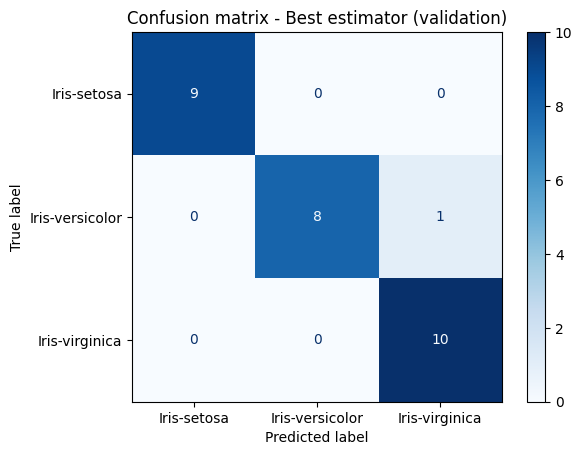

In [56]:

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = grid.predict(X_Val) #Prediction on the VALIDATION set (the test set stays locked)
print(classification_report(y_Val, y_pred))

cm = confusion_matrix(y_Val, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=grid.classes_)
disp.plot(cmap='Blues')
plt.title("Confusion matrix - Best estimator (validation)")
plt.show()

##Best estimator
###GridSearchCV --> Best CV Score: 0.9647 -->96,45%

**Check point6** Using Random Search

###Randomized search

Although an hyperparameter optimization method, it doesn't try all possible combinations.
It selects a fixed number of randomly picked combinations determined by n_iter.

It is usually more efficient and faster regharding big data searches and contiuous values. The computational cost is smaller and allows to try thousands of combinations.

 'clf__C': loguniform(1e-3, 1e2) determines the search space for the hyperparameter C of the model inside RandomizedSearchCV. Completely related to LogisticRegression, controls the complexity of the model. The best value is selected

In [57]:
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, KFold

# Encapsulate feature scaling, PCA, and classification into a single pipeline.
# This prevents data leakage by fitting transformers strictly on training folds.
pipe = Pipeline([
    ("scaler", StandardScaler()),                 # Step 1: Standardize features (mean=0, variance=1)
    ("pca", PCA()),                               # Step 2: Apply Principal Component Analysis
    ("clf", LogisticRegression(max_iter=1000))    # Step 3: Train Logistic Regression classifier
])

# Define the search space using discrete lists or continuous probability distributions.
# Syntax: 'stepname__parametername' routes the parameter to the correct pipeline step.
param_distributions = {
    'pca__n_components': [1, 2, 3, 4],            # Discrete list of component choices
    'clf__C': loguniform(1e-3, 1e2)               # Continuous log-uniform distribution between 0.001 and 100
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Instantiate RandomizedSearchCV:
# - Randomly samples from 'param_distributions' for 'n_iter' combinations
# - Evaluates each combination using the 5-fold CV strategy
# - Automatically refits the best model on the full training set (X_train, y_train)
random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_distributions,
    n_iter=10,             # Number of random parameter combinations to evaluate
    cv=kf,                 # Cross-validation splitting scheme
    scoring='accuracy',    # Evaluation metric
    random_state=42,       # Seed for reproducible random sampling
    n_jobs=-1              # Utilize all available CPU cores for parallel processing
)
random_search.fit(X_train, y_train)

# Print the top-performing hyperparameter combination found across random iterations
print("Best parameters found:", random_search.best_params_)

# Print the highest average validation accuracy score achieved
print(f"Best mean CV score: {random_search.best_score_:.4f}")

# Extract the final retrained Pipeline object configured with optimal parameters
best_model = random_search.best_estimator_

# Convert the search history dictionary into a DataFrame for structured inspection
results_df = pd.DataFrame(random_search.cv_results_)
print("\nSummary of tested parameter combinations:")
print(results_df[['param_pca__n_components', 'param_clf__C', 'mean_test_score', 'rank_test_score']])


Best parameters found: {'clf__C': np.float64(0.9846738873614566), 'pca__n_components': 3}
Best mean CV score: 0.9647

Summary of tested parameter combinations:
   param_pca__n_components  param_clf__C  mean_test_score  rank_test_score
0                        1      0.074593         0.869853                5
1                        4      0.008264         0.810294                7
2                        3      0.984674         0.964706                1
3                        3      0.169498         0.905147                4
4                        4      0.001952         0.643382                8
5                        4      0.046617         0.857353                6
6                        2      3.470267         0.905882                2
7                        4      0.001915         0.643382                8
8                        2     14.528247         0.905882                2
9                        4      0.001009         0.619853               10


                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00         9
Iris-versicolor       1.00      0.89      0.94         9
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.96        28
      macro avg       0.97      0.96      0.96        28
   weighted avg       0.97      0.96      0.96        28



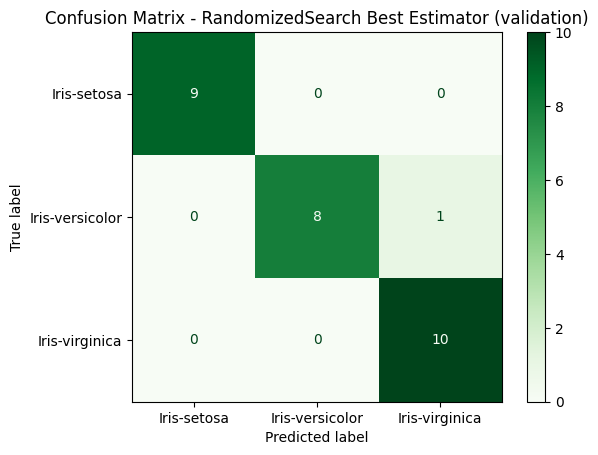

In [58]:
# Evaluation of RandomizedSearchCV best estimator on the VALIDATION set (test set still locked)
y_pred_random = random_search.predict(X_Val)

print(classification_report(y_Val, y_pred_random))

cm_random = confusion_matrix(y_Val, y_pred_random)
disp_random = ConfusionMatrixDisplay(confusion_matrix=cm_random, display_labels=random_search.classes_)
disp_random.plot(cmap='Greens')
plt.title("Confusion Matrix - RandomizedSearch Best Estimator (validation)")
plt.show()

###Gaussian Naive Bayes vs. LogisticRegression

In [59]:
#Other classifier: Gaussian Naive Bayes, tuning var_smoothing
from sklearn.naive_bayes import GaussianNB

pipe_nb = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("clf", GaussianNB())
])

nb_params = {
    'pca__n_components': [1, 2, 3, 4],
    'clf__var_smoothing': np.logspace(-9, 0, 10)   # 1e-9 ... 1
}

kf_nb = KFold(n_splits=5, shuffle=True, random_state=42)
nb_grid = GridSearchCV(pipe_nb, param_grid=nb_params, cv=kf_nb).fit(X_train, y_train)

print("Naive Bayes best parameters:", nb_grid.best_params_)

# Compare the models using cross-validation (train) and validation, NOT the test set
print(f"\nLogReg (GridSearchCV) -> CV: {grid.best_score_:.4f} | Validation: {grid.score(X_Val, y_Val):.4f}")
print(f"GaussianNB (GridSearchCV) -> CV: {nb_grid.best_score_:.4f} | Validation: {nb_grid.score(X_Val, y_Val):.4f}")

Naive Bayes best parameters: {'clf__var_smoothing': np.float64(0.001), 'pca__n_components': 4}

LogReg (GridSearchCV) -> CV: 0.9647 | Validation: 0.9643
GaussianNB (GridSearchCV) -> CV: 0.9176 | Validation: 0.9286


In [60]:
print(f"GaussianNB     best CV score: {nb_grid.best_score_:.4f} -> {nb_grid.best_params_}")

final_search = max([grid, random_search, nb_grid], key=lambda s: s.best_score_)
print("\nChosen model:", final_search.best_estimator_)

GaussianNB     best CV score: 0.9176 -> {'clf__var_smoothing': np.float64(0.001), 'pca__n_components': 4}

Chosen model: Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA(n_components=3)),
                ('clf', LogisticRegression(C=1, max_iter=1000))])


- Adding LDA between PCA and logistic regression showed how a supervised projection separates the classes in 2D.
- Comparing K=3, 5, 10 and Leave-One-Out showed the trade-off between number of experiments, time, bias and variance.
- Gaussian Naive Bayes (tuning var_smoothing) was compared with logistic regression using cross-validation, not the test set.


# Put in a note

GridSearchCV   best CV score: 0.9647 -> {'clf__C': 1, 'pca__n_components': 3}
RandomSearchCV best CV score: 0.9647 -> {'clf__C': np.float64(0.9846738873614566), 'pca__n_components': 3}
GaussianNB     best CV score: 0.9176 -> {'clf__var_smoothing': np.float64(0.001), 'pca__n_components': 4}

Chosen model: Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA(n_components=3)),
                ('clf', LogisticRegression(C=1, max_iter=1000))])

=== FINAL TEST REPORT ===
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        13
Iris-versicolor       1.00      0.92      0.96        13
 Iris-virginica       0.92      1.00      0.96        12

       accuracy                           0.97        38
      macro avg       0.97      0.97      0.97        38
   weighted avg       0.98      0.97      0.97        38



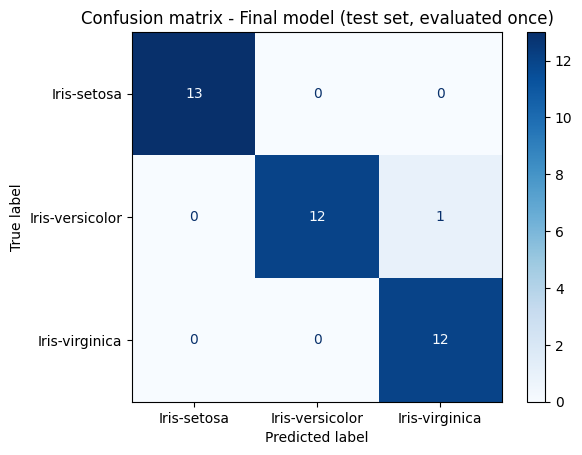

In [61]:
#Final evaluation on the TEST set: done ONCE, with the model chosen by cross-validation
print(f"GridSearchCV   best CV score: {grid.best_score_:.4f} -> {grid.best_params_}")
print(f"RandomSearchCV best CV score: {random_search.best_score_:.4f} -> {random_search.best_params_}")
print(f"GaussianNB     best CV score: {nb_grid.best_score_:.4f} -> {nb_grid.best_params_}")

final_search = max([grid, random_search, nb_grid], key=lambda s: s.best_score_)
print("\nChosen model:", final_search.best_estimator_)

y_pred_final = final_search.predict(X_test)
print("\n=== FINAL TEST REPORT ===")
print(classification_report(y_test, y_pred_final))

cm_final = confusion_matrix(y_test, y_pred_final)
ConfusionMatrixDisplay(cm_final, display_labels=final_search.classes_).plot(cmap='Blues')
plt.title("Confusion matrix - Final model (test set, evaluated once)")
plt.show()

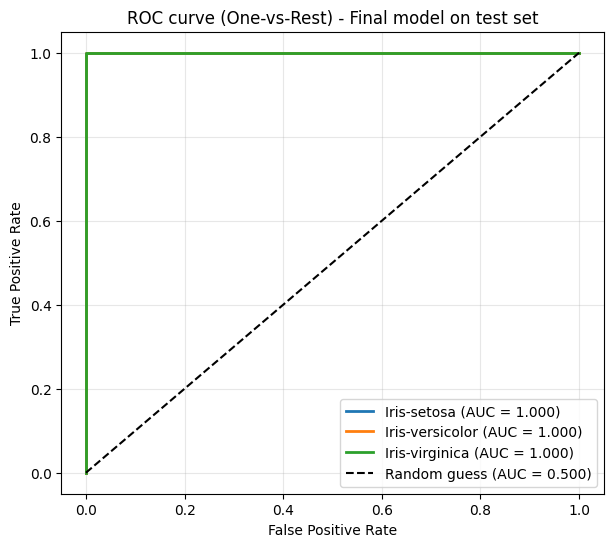

Macro-average ROC AUC (OvR): 1.0000


In [62]:
#ROC curve and AUC on the TEST set (One-vs-Rest, one curve per class)
#This is part of the same final evaluation: no tuning is done after looking at it
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

classes = final_search.classes_
y_test_bin = label_binarize(y_test, classes=classes)   # one 0/1 column per class
y_score = final_search.predict_proba(X_test)           # probability of each class

plt.figure(figsize=(7, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve (One-vs-Rest) - Final model on test set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

#Single AUC value for the whole multiclass problem
macro_auc = roc_auc_score(y_test, y_score, multi_class="ovr", average="macro")
print(f"Macro-average ROC AUC (OvR): {macro_auc:.4f}")

# Conclusions

- The test set was split first (75:25) and used only once, at the very end.
- Hyperparameters (PCA n_components, C) were chosen with 5-fold cross-validation on the training data only.
- A single holdout result changes with the random seed in small datasets (Check point 2); cross-validation gives a more stable estimate (mean ± std).
- Adding LDA between PCA and logistic regression showed how a supervised projection separates the classes in 2D.
- Comparing K=3, 5, 10 and Leave-One-Out showed the trade-off between number of experiments, time, bias and variance.
- GridSearchCV, RandomizedSearchCV and Gaussian Naive Bayes were compared by their CV score, and only the best one was evaluated on the test set.
- The ROC curves (One-vs-Rest) and the macro AUC confirm how well the final model separates the three classes on the test set.

In [63]:
print()